<a href="https://colab.research.google.com/github/WendelLeander/PhishEvade/blob/main/Modules/9_preliminary_findings_results_writeup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 9 — Preliminary Findings and Results Writeup
**Thesis:** Obfuscation-Aware Feature Engineering for Evasion-Heavy Phishing URL Detection

This notebook turns the executed Milestone 8 outputs into a panel-ready **preliminary findings draft**. It does not fit models, change thresholds, or invent missing evidence. Its tables, plots, and narrative are generated from the evaluation files so the text stays consistent with the numbers. The exported draft is `Results/milestone9/preliminary_findings_draft.md`.

Run Milestone 8 first (it writes `Results/milestone8/`). On Google Colab, run the *Get the repository* cell first; if Milestone 8 ran in the same Colab session, its results are already in the clone, otherwise push `Results/milestone8/` to GitHub before running this notebook. Locally, run from `Modules/` or the project root. Results come from the dated dataset's fixed split (train / test / evasion holdout) and remain marked **provisional** until confirmed on independent data.

## Get the repository (Colab)
This notebook reads the models, metrics and dataset files from the repository folders. On **Google Colab** the cell below clones the GitHub repository (or pulls the latest commits if it was already cloned in this session) and moves into `Modules/`, so every input comes from the same pushed snapshot. Push the outputs of the previous milestones before running it. When the notebook is run locally inside the repository, the cell does nothing. Outputs are written inside the clone; download them from Colab's file panel (or push them) before the session ends.

In [ ]:
# Get the repository. On Google Colab (stateless) this clones the GitHub repo, or pulls the latest
# commits if it was already cloned in this session, then moves into Modules/. Run locally inside the
# repo, it does nothing. The notebook reads Dataset/, Models/, Metrics/ (and Results/) from the clone.
import os, sys, subprocess
REPO_URL  = "https://github.com/WendelLeander/PhishEvade.git"
REPO_DIR  = "/content/PhishEvade"

def ensure_repo(in_colab=("google.colab" in sys.modules)):
    if not in_colab:
        print("Not running on Colab: using the local repository.")
        return
    if os.path.isdir(os.path.join(REPO_DIR, ".git")):
        subprocess.run(["git", "-C", REPO_DIR, "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
    os.chdir(os.path.join(REPO_DIR, "Modules"))
    head = subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--format=%h %cd %s", "--date=short"],
                          capture_output=True, text=True).stdout.strip()
    print("Repository ready at", os.getcwd(), "| latest commit:", head)

ensure_repo()

Repository ready at /content/PhishEvade/Modules | latest commit: 0dabedd 2026-11-11 added m8 results


In [ ]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents]
           if (p/'Results/milestone8/evaluation_metadata.json').is_file()),None)
assert ROOT is not None,'Run Module 8 or copy the supplied Results/milestone8 folder into the repository.'
IN=ROOT/'Results/milestone8'; OUT=ROOT/'Results/milestone9';OUT.mkdir(parents=True,exist_ok=True)
def read(name):return pd.read_csv(IN/(name+'.csv'))
m=read('performance_comparison_15');p=read('paired_comparisons');s=read('subset_evaluation');
r=read('resource_comparison');q=read('data_quality'); imp=read('permutation_importance_combined')
t=read('tuned_threshold_sensitivity');support=read('subset_support')
h=read('evasion_holdout_comparison_15');hp=read('evasion_holdout_paired_comparisons')
gfpr=read('benign_group_fpr');hdom=read('evasion_holdout_domain_overlap')
meta=json.loads((IN/'evaluation_metadata.json').read_text())
assert len(m)==15 and m.combination.is_unique and m.threshold.eq(.5).all()
assert m.groupby('classifier').feature_set.nunique().eq(3).all() and m.classifier.nunique()==5
assert (m[['tn','fp','fn','tp']].sum(axis=1)==meta['n_test']).all()
assert set(m.combination)==set(r.combination)==set(t.combination)==set(h.combination) and len(hp)==10
M=m.set_index('combination');R=r.set_index('combination');Q=q.set_index('check').value;H=h.set_index('combination')
n_test=meta['n_test'];n_pos=meta['class_counts']['phishing'];n_neg=meta['class_counts']['benign']
n_train=meta['n_train'];hc=meta['holdout_class_counts'];hd=meta['holdout_phishing_dates']
base=M.loc['logistic_regression__level_1']; ranked=m.sort_values(['f1','fpr'],ascending=[False,True])
best=ranked.iloc[0];second=ranked.iloc[1];cv_best=m.loc[m.cv_f1.idxmax()]
F=['Level 1','Level 2','Combined']
C=['Logistic Regression','Random Forest','XGBoost','Naive Bayes','AdaBoost']
def pct(x):return f'{100*x:.2f}%'
def pp(x):return f'{100*x:+.2f} pp'
def label(row):return f'{row.classifier} / {row.feature_set}'
def mdtable(d):
    cells=lambda row:'| '+' | '.join(str(v).replace('|',chr(92)+'|') for v in row)+' |'
    return '\n'.join([cells(d.columns),cells(['---']*len(d.columns)),*(cells(row) for row in d.itertuples(index=False,name=None))])
def show(text):display(Markdown(text))
sections=[]
def section(text):
    text=text.strip();sections.append(text);show(text)
def chart(name,caption):
    path=IN/'figures'/name
    assert path.is_file(),f'Missing Module 8 figure: {name}'
    display(Image(filename=str(path),width=1000))
    sections.append(f'![{caption}](../milestone8/figures/{name})')
print('Source:',meta['source_commit_reviewed'],'|',meta['status'])

Source: dated dataset (split column: train / test / evasion_holdout) | PROVISIONAL: test set previously inspected; evasion holdout temporal on the phishing side only


## Draft text and evidence
The following cells render the draft in order. Findings are based on the fixed 0.5 decision rule unless a paragraph explicitly says otherwise. Positive changes in F1 or recall are favorable; negative changes in FPR or FNR are favorable. Percentage points (pp) are absolute differences.

# Preliminary findings: PhishEvade

**Status:** Preliminary analysis for panel feedback. Scaling is fitted on the training rows only and the evasion holdout was never used for training or tuning; the remaining limitations (test-set reuse, undated benign URLs, shared domains) are described below.

## 1. Evaluation design

We evaluated five classifiers under three feature configurations: Level 1 (3 basic length features), Level 2 (10 obfuscation-aware features), and Combined (all 13). The dataset carries a fixed split. Its newest phishing URLs (1,080 URLs first seen between 2026-03-01 and 2026-05-25, with first-seen dates cross-checked against PhishTank and PhishStats) and 1,080 benign URLs form an **evasion-heavy holdout** that was excluded from training, tuning and threshold selection. The remaining URLs were split 80:20 into 6,272 training rows and 1,568 test rows (784 benign and 784 phishing). Module 7 selected hyperparameters using F1 in five-fold GridSearchCV on the training rows, with all feature scaling fitted inside each model pipeline on training rows only. For evaluation, we independently loaded the saved models, flagged scores at or above 0.5 as phishing, and compared the results with the Module 6 Logistic Regression Level 1 baseline. F1 was our main performance measure on the test set; recall, false negative rate (FNR), and false positive rate (FPR) showed the operational cost of missed threats and false alarms. Tuned thresholds are reported only as an adjustment aid.

The artifact checks confirmed that all 15 saved model files matched the manifest, and that their confusion matrices reproduced Module 7's recorded results. The separately loaded Module 6 baseline reproduced the Logistic Regression Level 1 reference. These checks establish that the saved models produce the expected outputs on the fixed test partition and the evasion holdout. They do not make the previously displayed test set untouched.

## 2. Full comparison on the test set at the 0.5 threshold

| Classifier | Features | Accuracy | Precision | Recall | F1 | FPR | FNR | ΔF1 vs LR (pp) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Logistic Regression | Level 1 | 62.76% | 64.33% | 57.27% | 60.59% | 31.76% | 42.73% | +0.00 |
| Logistic Regression | Level 2 | 64.03% | 61.88% | 73.09% | 67.02% | 45.03% | 26.91% | +6.42 |
| Logistic Regression | Combined | 70.34% | 70.42% | 70.15% | 70.29% | 29.46% | 29.85% | +9.69 |
| Random Forest | Level 1 | 89.16% | 92.40% | 85.33% | 88.73% | 7.02% | 14.67% | +28.13 |
| Random Forest | Level 2 | 92.47% | 95.12% | 89.54% | 92.25% | 4.59% | 10.46% | +31.65 |
| Random Forest | Combined | 94.07% | 96.63% | 91.33% | 93.90% | 3.19% | 8.67% | +33.31 |
| XGBoost | Level 1 | 88.90% | 91.55% | 85.71% | 88.54% | 7.91% | 14.29% | +27.94 |
| XGBoost | Level 2 | 91.77% | 93.84% | 89.41% | 91.57% | 5.87% | 10.59% | +30.98 |
| XGBoost | Combined | 94.52% | 96.04% | 92.86% | 94.42% | 3.83% | 7.14% | +33.83 |
| Naive Bayes | Level 1 | 76.47% | 82.88% | 66.71% | 73.92% | 13.78% | 33.29% | +13.33 |
| Naive Bayes | Level 2 | 55.74% | 53.13% | 97.45% | 68.77% | 85.97% | 2.55% | +8.17 |
| Naive Bayes | Combined | 56.25% | 53.53% | 94.90% | 68.45% | 82.40% | 5.10% | +7.85 |
| AdaBoost | Level 1 | 86.03% | 88.75% | 82.53% | 85.53% | 10.46% | 17.47% | +24.93 |
| AdaBoost | Level 2 | 88.58% | 90.50% | 86.22% | 88.31% | 9.06% | 13.78% | +27.71 |
| AdaBoost | Combined | 92.86% | 94.44% | 91.07% | 92.73% | 5.36% | 8.93% | +32.13 |

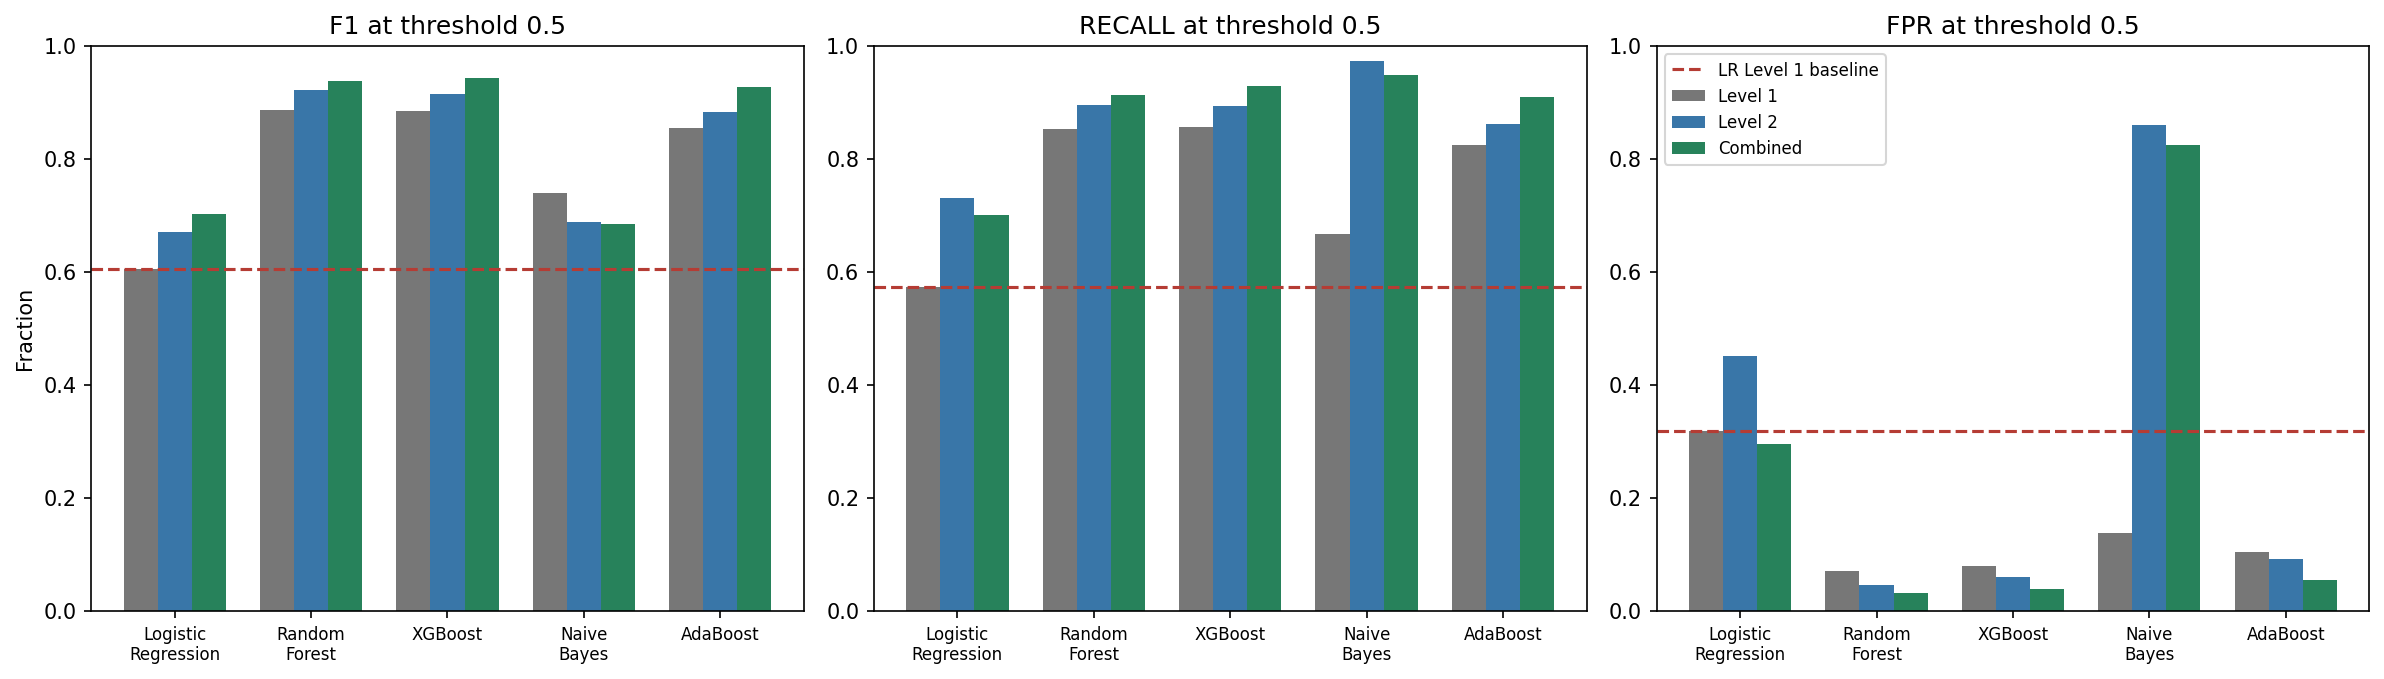

The baseline reached **60.59% F1** and **57.27% recall**, with **335 missed phishing URLs** and **249 false alarms**. **XGBoost / Combined** had the highest observed test F1 (**94.42%**, 95% row-bootstrap interval 93.31%–95.55%), with **92.86% recall** and **3.83% FPR**. It missed 56 of 784 phishing URLs and flagged 30 of 784 benign URLs. Compared with the baseline, that is 279 fewer misses and 219 fewer false alarms. Its F1 was +33.83 pp above the baseline.

**Random Forest / Combined** followed at 93.90% F1, with 91.33% recall and 3.19% FPR. The difference between these two top observed F1 scores was only 0.52 pp. We treat both as candidates for confirmation; ranking them on an already inspected test split does not establish a reliable winner for future URLs. The highest **training-CV** F1 belonged to XGBoost / Combined (94.05%), so the CV ranking can be distinguished from the observed test ranking.

In [ ]:
section(f"""
# Preliminary findings: PhishEvade

**Status:** Preliminary analysis for panel feedback. Scaling is fitted on the training rows only and the evasion holdout was never used for training or tuning; the remaining limitations (test-set reuse, undated benign URLs, shared domains) are described below.

## 1. Evaluation design

We evaluated five classifiers under three feature configurations: Level 1 (3 basic length features), Level 2 (10 obfuscation-aware features), and Combined (all 13). The dataset carries a fixed split. Its newest phishing URLs ({hc['phishing']:,} URLs first seen between {hd[0]} and {hd[1]}, with first-seen dates cross-checked against PhishTank and PhishStats) and {hc['benign']:,} benign URLs form an **evasion-heavy holdout** that was excluded from training, tuning and threshold selection. The remaining URLs were split 80:20 into {n_train:,} training rows and {n_test:,} test rows ({n_neg:,} benign and {n_pos:,} phishing). Module 7 selected hyperparameters using F1 in five-fold GridSearchCV on the training rows, with all feature scaling fitted inside each model pipeline on training rows only. For evaluation, we independently loaded the saved models, flagged scores at or above 0.5 as phishing, and compared the results with the Module 6 Logistic Regression Level 1 baseline. F1 was our main performance measure on the test set; recall, false negative rate (FNR), and false positive rate (FPR) showed the operational cost of missed threats and false alarms. Tuned thresholds are reported only as an adjustment aid.

The artifact checks confirmed that all 15 saved model files matched the manifest, and that their confusion matrices reproduced Module 7's recorded results. The separately loaded Module 6 baseline reproduced the Logistic Regression Level 1 reference. These checks establish that the saved models produce the expected outputs on the fixed test partition and the evasion holdout. They do not make the previously displayed test set untouched.
""")
view=m[['classifier','feature_set','accuracy','precision','recall','f1','fpr','fnr','delta_f1_vs_baseline_pp']].copy()
for col in ['accuracy','precision','recall','f1','fpr','fnr']:view[col]=view[col].map(pct)
view['delta_f1_vs_baseline_pp']=view.delta_f1_vs_baseline_pp.map(lambda x:f'{x:+.2f}')
view.columns=['Classifier','Features','Accuracy','Precision','Recall','F1','FPR','FNR','ΔF1 vs LR (pp)']
section('## 2. Full comparison on the test set at the 0.5 threshold\n\n'+mdtable(view))
chart('01_feature_comparison.png','F1, recall and FPR for all 15 combinations relative to the Level 1 Logistic Regression baseline.')
section(f"""
The baseline reached **{pct(base.f1)} F1** and **{pct(base.recall)} recall**, with **{int(base.fn)} missed phishing URLs** and **{int(base.fp)} false alarms**. **{label(best)}** had the highest observed test F1 (**{pct(best.f1)}**, 95% row-bootstrap interval {pct(best.f1_ci_low)}–{pct(best.f1_ci_high)}), with **{pct(best.recall)} recall** and **{pct(best.fpr)} FPR**. It missed {int(best.fn)} of {n_pos:,} phishing URLs and flagged {int(best.fp)} of {n_neg:,} benign URLs. Compared with the baseline, that is {int(base.fn-best.fn)} fewer misses and {int(base.fp-best.fp)} fewer false alarms. Its F1 was {pp(best.f1-base.f1)} above the baseline.

**{label(second)}** followed at {pct(second.f1)} F1, with {pct(second.recall)} recall and {pct(second.fpr)} FPR. The difference between these two top observed F1 scores was only {100*(best.f1-second.f1):.2f} pp. We treat both as candidates for confirmation; ranking them on an already inspected test split does not establish a reliable winner for future URLs. The highest **training-CV** F1 belonged to {label(cv_best)} ({pct(cv_best.cv_f1)}), so the CV ranking can be distinguished from the observed test ranking.
""")

## 3. Did the Level 2 features improve detection on the test set?

| Classifier | Features | ΔF1 (pp) | 95% ΔF1 interval (pp) | ΔRecall (pp) | ΔFPR (pp) | F1 p (Holm) | FPR reduction p (Holm) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Logistic Regression | Level 2 | 6.42 | +3.80 to +9.04 | 15.82 | 13.27 | 0.0048 | 1 |
| Logistic Regression | Combined | 9.69 | +6.46 to +12.73 | 12.88 | -2.3 | 0.0048 | 1 |
| Random Forest | Level 2 | 3.52 | +1.82 to +5.14 | 4.21 | -2.42 | 0.0048 | 0.189 |
| Random Forest | Combined | 5.17 | +3.72 to +6.61 | 5.99 | -3.83 | 0.0048 | 0.000339 |
| XGBoost | Level 2 | 3.04 | +1.19 to +4.82 | 3.7 | -2.04 | 0.0048 | 0.403 |
| XGBoost | Combined | 5.89 | +4.33 to +7.48 | 7.14 | -4.08 | 0.0048 | 0.000609 |
| Naive Bayes | Level 2 | -5.16 | -7.58 to -2.56 | 30.74 | 72.19 | 0.0048 | 1 |
| Naive Bayes | Combined | -5.48 | -7.86 to -2.99 | 28.19 | 68.62 | 0.0048 | 1 |
| AdaBoost | Level 2 | 2.78 | +0.78 to +4.78 | 3.7 | -1.4 | 0.0072 | 1 |
| AdaBoost | Combined | 7.2 | +5.61 to +8.88 | 8.55 | -5.1 | 0.0048 | 6.01e-05 |

The feature effect is best assessed **within the same classifier**. Combined increased observed test F1 in **4 of 5** classifiers, while Level 2 alone increased it in **4 of 5**. Combined improved F1 **and** reduced FPR relative to the same classifier's Level 1 version, with Holm-adjusted p-values below 0.05 for both tests, for: **Random Forest, XGBoost, AdaBoost**. Logistic Regression illustrates why F1 and FPR must be read together: Level 2 alone changed F1 by +6.42 pp and FPR by +13.27 pp, while the combined version had FPR 29.46% and F1 70.29%.

Classifiers whose Combined F1 fell below their Level 1 F1: **Naive Bayes**. For Naive Bayes, Combined changed recall from 66.71% to 94.90% and FPR from 13.78% to 82.40%, lowering F1 by 5.48 pp. The observed pattern supports using the engineered features with suitable classifiers; it does not show that adding them always improves detection.

The paired bootstrap intervals use the same resampled test rows for each model. They describe the precision of observed F1 differences on this dataset. The paired F1 randomization, overall-error, and benign FPR tests use Holm correction across the 24 contrasts per test family. They are conditional on this split; the temporal question is answered by the evasion holdout in the next section. The F1 intervals are exploratory and unadjusted for multiple comparisons.

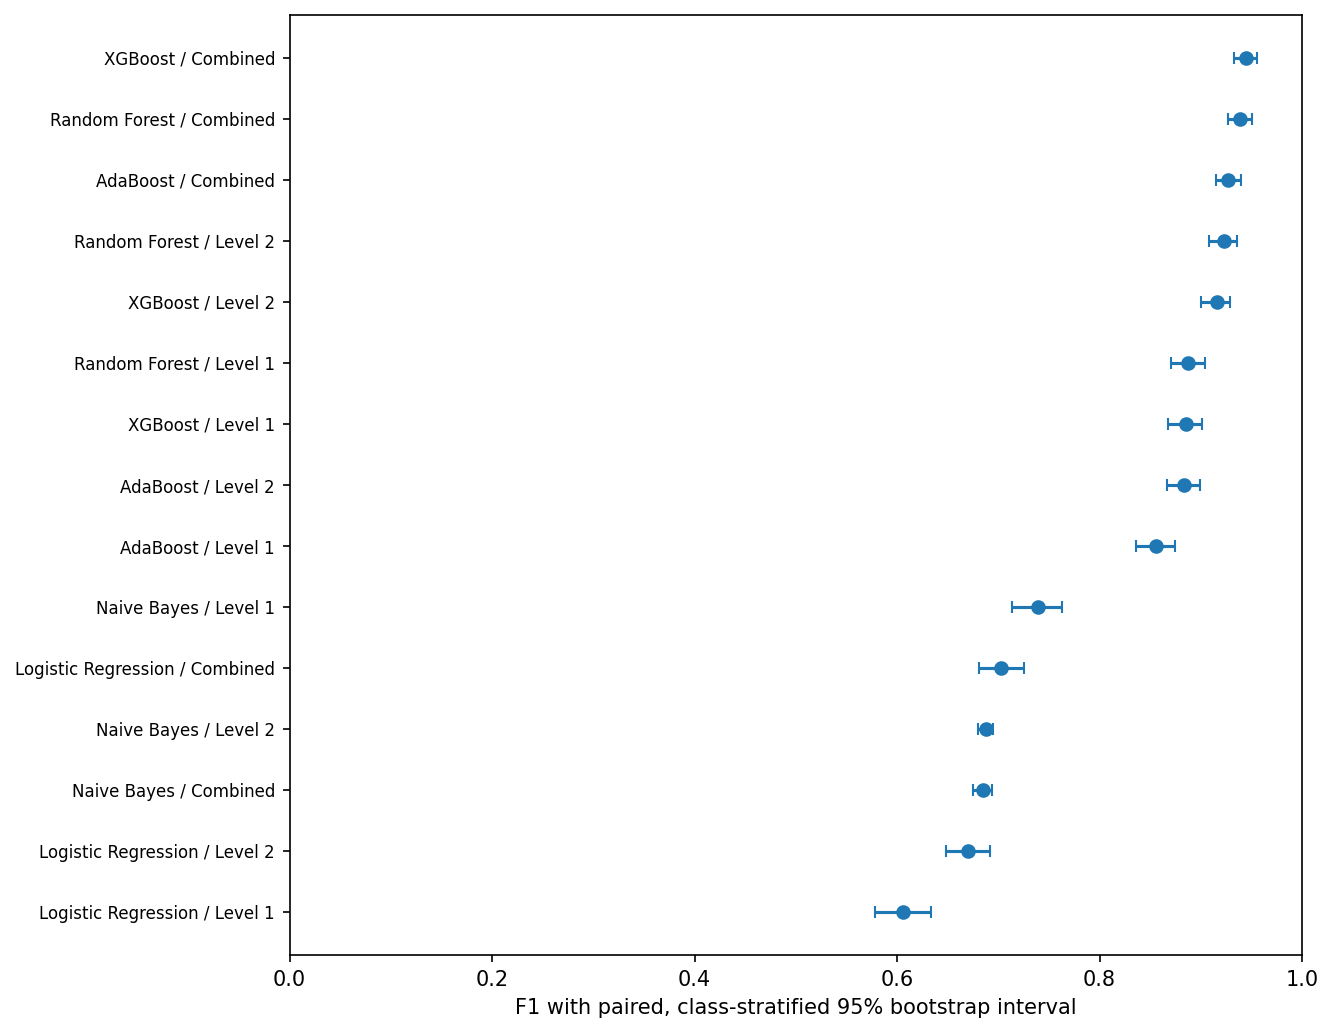

In [ ]:
abl=[]
for c in C:
    local=m[m.classifier==c].set_index('feature_set')
    for fs in F[1:]:
        a=local.loc[fs];b=local.loc['Level 1'];d=p[(p.combination==a.combination)&(p.reference==b.combination)&p.family.str.startswith('within')].iloc[0]
        abl.append({'Classifier':c,'Features':fs,'ΔF1 (pp)':round(d.delta_f1_pp,2),
            '95% ΔF1 interval (pp)':f'{d.delta_f1_ci_low_pp:+.2f} to {d.delta_f1_ci_high_pp:+.2f}',
            'ΔRecall (pp)':round(100*(a.recall-b.recall),2),'ΔFPR (pp)':round(d.delta_fpr_pp,2),
            'F1 p (Holm)':f'{d.f1_permutation_p_holm:.3g}','FPR reduction p (Holm)':f'{d.fpr_reduction_p_holm:.3g}',
            '_f1p':d.f1_permutation_p_holm,'_fprp':d.fpr_reduction_p_holm})
a=pd.DataFrame(abl);a.drop(columns=['_f1p','_fprp']).to_csv(OUT/'feature_ablation_summary.csv',index=False)
section('## 3. Did the Level 2 features improve detection on the test set?\n\n'+mdtable(a.drop(columns=['_f1p','_fprp'])))
comp=a[a.Features=='Combined'];only=a[a.Features=='Level 2']
both=comp[(comp['ΔF1 (pp)']>0)&(comp._f1p<.05)&(comp['ΔFPR (pp)']<0)&(comp._fprp<.05)].Classifier.tolist()
worse=comp[comp['ΔF1 (pp)']<0].Classifier.tolist()
def names(xs):return ', '.join(xs) if xs else 'none'
lc=m[m.classifier=='Logistic Regression'].set_index('feature_set')
worse_txt=''
for c in worse:
    loc=m[m.classifier==c].set_index('feature_set')
    worse_txt+=(f" For {c}, Combined changed recall from {pct(loc.loc['Level 1','recall'])} to {pct(loc.loc['Combined','recall'])} "
                f"and FPR from {pct(loc.loc['Level 1','fpr'])} to {pct(loc.loc['Combined','fpr'])}, lowering F1 by {abs(comp.set_index('Classifier').loc[c,'ΔF1 (pp)']):.2f} pp.")
section(f"""
The feature effect is best assessed **within the same classifier**. Combined increased observed test F1 in **{(comp['ΔF1 (pp)']>0).sum()} of 5** classifiers, while Level 2 alone increased it in **{(only['ΔF1 (pp)']>0).sum()} of 5**. Combined improved F1 **and** reduced FPR relative to the same classifier's Level 1 version, with Holm-adjusted p-values below 0.05 for both tests, for: **{names(both)}**. Logistic Regression illustrates why F1 and FPR must be read together: Level 2 alone changed F1 by {pp(lc.loc['Level 2','f1']-lc.loc['Level 1','f1'])} and FPR by {pp(lc.loc['Level 2','fpr']-lc.loc['Level 1','fpr'])}, while the combined version had FPR {pct(lc.loc['Combined','fpr'])} and F1 {pct(lc.loc['Combined','f1'])}.

Classifiers whose Combined F1 fell below their Level 1 F1: **{names(worse)}**.{worse_txt} The observed pattern supports using the engineered features with suitable classifiers; it does not show that adding them always improves detection.

The paired bootstrap intervals use the same resampled test rows for each model. They describe the precision of observed F1 differences on this dataset. The paired F1 randomization, overall-error, and benign FPR tests use Holm correction across the 24 contrasts per test family. They are conditional on this split; the temporal question is answered by the evasion holdout in the next section. The F1 intervals are exploratory and unadjusted for multiple comparisons.
""")
chart('02_f1_intervals.png','Observed hold-out F1 with 95% class-stratified bootstrap intervals.')

## 4. Evasion-heavy holdout: newest phishing URLs (1,080 phishing, first seen 2026-03-01 to 2026-05-25; 1,080 benign)

| Classifier | Features | Recall | FNR | FPR | F1 | Missed (FN) | False alarms (FP) | Recall vs. test (pp) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Logistic Regression | Level 1 | 75.93% | 24.07% | 27.13% | 74.78% | 260 | 293 | +18.66 |
| Logistic Regression | Level 2 | 78.61% | 21.39% | 41.85% | 71.31% | 231 | 452 | +5.52 |
| Logistic Regression | Combined | 67.22% | 32.78% | 26.94% | 69.24% | 354 | 291 | -2.93 |
| Random Forest | Level 1 | 73.89% | 26.11% | 7.13% | 81.64% | 282 | 77 | -11.44 |
| Random Forest | Level 2 | 71.76% | 28.24% | 3.61% | 81.84% | 305 | 39 | -17.78 |
| Random Forest | Combined | 79.54% | 20.46% | 2.31% | 87.47% | 221 | 25 | -11.79 |
| XGBoost | Level 1 | 73.89% | 26.11% | 7.41% | 81.51% | 282 | 80 | -11.83 |
| XGBoost | Level 2 | 73.33% | 26.67% | 4.72% | 82.37% | 288 | 51 | -16.08 |
| XGBoost | Combined | 81.11% | 18.89% | 4.07% | 87.60% | 204 | 44 | -11.75 |
| Naive Bayes | Level 1 | 58.61% | 41.39% | 12.50% | 68.51% | 447 | 135 | -8.10 |
| Naive Bayes | Level 2 | 98.33% | 1.67% | 84.91% | 69.43% | 18 | 917 | +0.88 |
| Naive Bayes | Combined | 98.33% | 1.67% | 83.06% | 69.89% | 18 | 897 | +3.44 |
| AdaBoost | Level 1 | 76.76% | 23.24% | 9.63% | 82.36% | 251 | 104 | -5.77 |
| AdaBoost | Level 2 | 70.56% | 29.44% | 8.15% | 78.96% | 318 | 88 | -15.67 |
| AdaBoost | Combined | 81.94% | 18.06% | 4.91% | 87.71% | 195 | 53 | -9.13 |

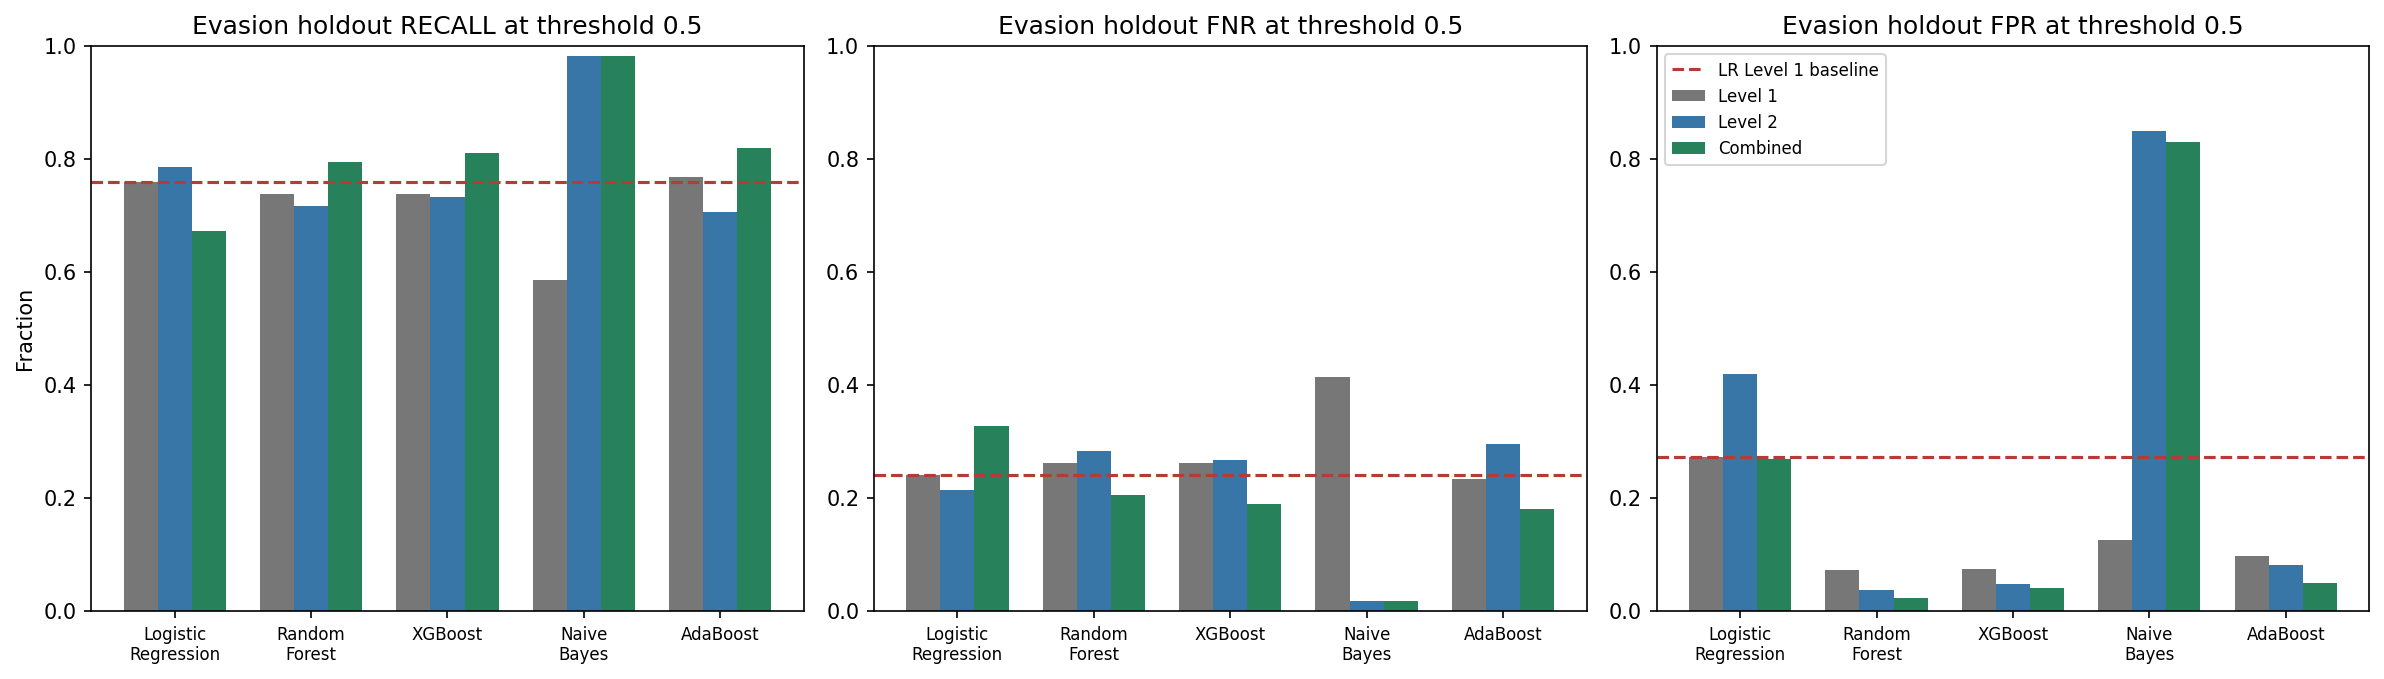

### Within-classifier feature comparison on the holdout

| Classifier | Features (vs. Level 1) | ΔRecall (pp) | ΔFPR (pp) | Newly caught | Newly missed | Recall p (Holm) | FPR p (Holm) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Logistic Regression | Level 2 | +2.69 | +14.72 | 118 | 89 | 0.154 | 2.73e-16 |
| Logistic Regression | Combined | -8.70 | -0.19 | 91 | 185 | 1.27e-07 | 0.958 |
| Random Forest | Level 2 | -2.13 | -3.52 | 125 | 148 | 0.366 | 0.000939 |
| Random Forest | Combined | +5.65 | -4.81 | 114 | 53 | 1.35e-05 | 3.68e-08 |
| XGBoost | Level 2 | -0.56 | -2.69 | 138 | 144 | 0.766 | 0.0166 |
| XGBoost | Combined | +7.22 | -3.33 | 141 | 63 | 3.4e-07 | 0.000939 |
| Naive Bayes | Level 2 | +39.72 | +72.41 | 438 | 9 | 9.15e-116 | 1.09e-214 |
| Naive Bayes | Combined | +39.72 | +70.56 | 437 | 8 | 8.03e-117 | 4.79e-210 |
| AdaBoost | Level 2 | -6.20 | -1.48 | 77 | 144 | 3.1e-05 | 0.422 |
| AdaBoost | Combined | +5.19 | -4.72 | 88 | 32 | 1.91e-06 | 2.23e-06 |

The evasion holdout tests generalization to phishing URLs **newer than anything in training**. At the 0.5 threshold, the Level 1 baseline caught **75.93%** of these newest phishing URLs (FNR 24.07%, 260 missed) with FPR 27.13%. The leading test-set model, **XGBoost / Combined**, caught **81.11%** (FNR 18.89%, 204 missed), a change of -11.75 pp from its test-set recall, with FPR 4.07%. Its own Level 1 version caught 73.89% (FPR 7.41%).

Within each classifier, Combined features significantly **increased** holdout recall over Level 1 (exact McNemar on phishing rows, Holm-adjusted p < 0.05) for: **Random Forest, XGBoost, Naive Bayes, AdaBoost**; of these, FPR did not rise for: **Random Forest, XGBoost, AdaBoost**. Combined significantly **decreased** holdout recall for: **Logistic Regression**. A recall gain is only useful if false alarms stay acceptable, so the FPR column must be read alongside it; a model that flags almost everything reaches high recall with an unusable FPR.

False alarms on the holdout's benign URLs for XGBoost / Combined were 2.89% on domain-only URLs, 5.65% on light-path URLs and 3.67% on obfuscated-looking benign URLs (per-group rates for every model are in `benign_group_fpr.csv`). The holdout is temporal but not domain-disjoint: 457 of its 1,080 phishing URLs share a registered domain with training URLs. For XGBoost / Combined, recall was 91.47% on those and 73.52% on the 623 phishing URLs from unseen domains, so part of the holdout performance reflects familiar domains. The holdout's benign URLs are not dated, so its FPR is not a time-based result.

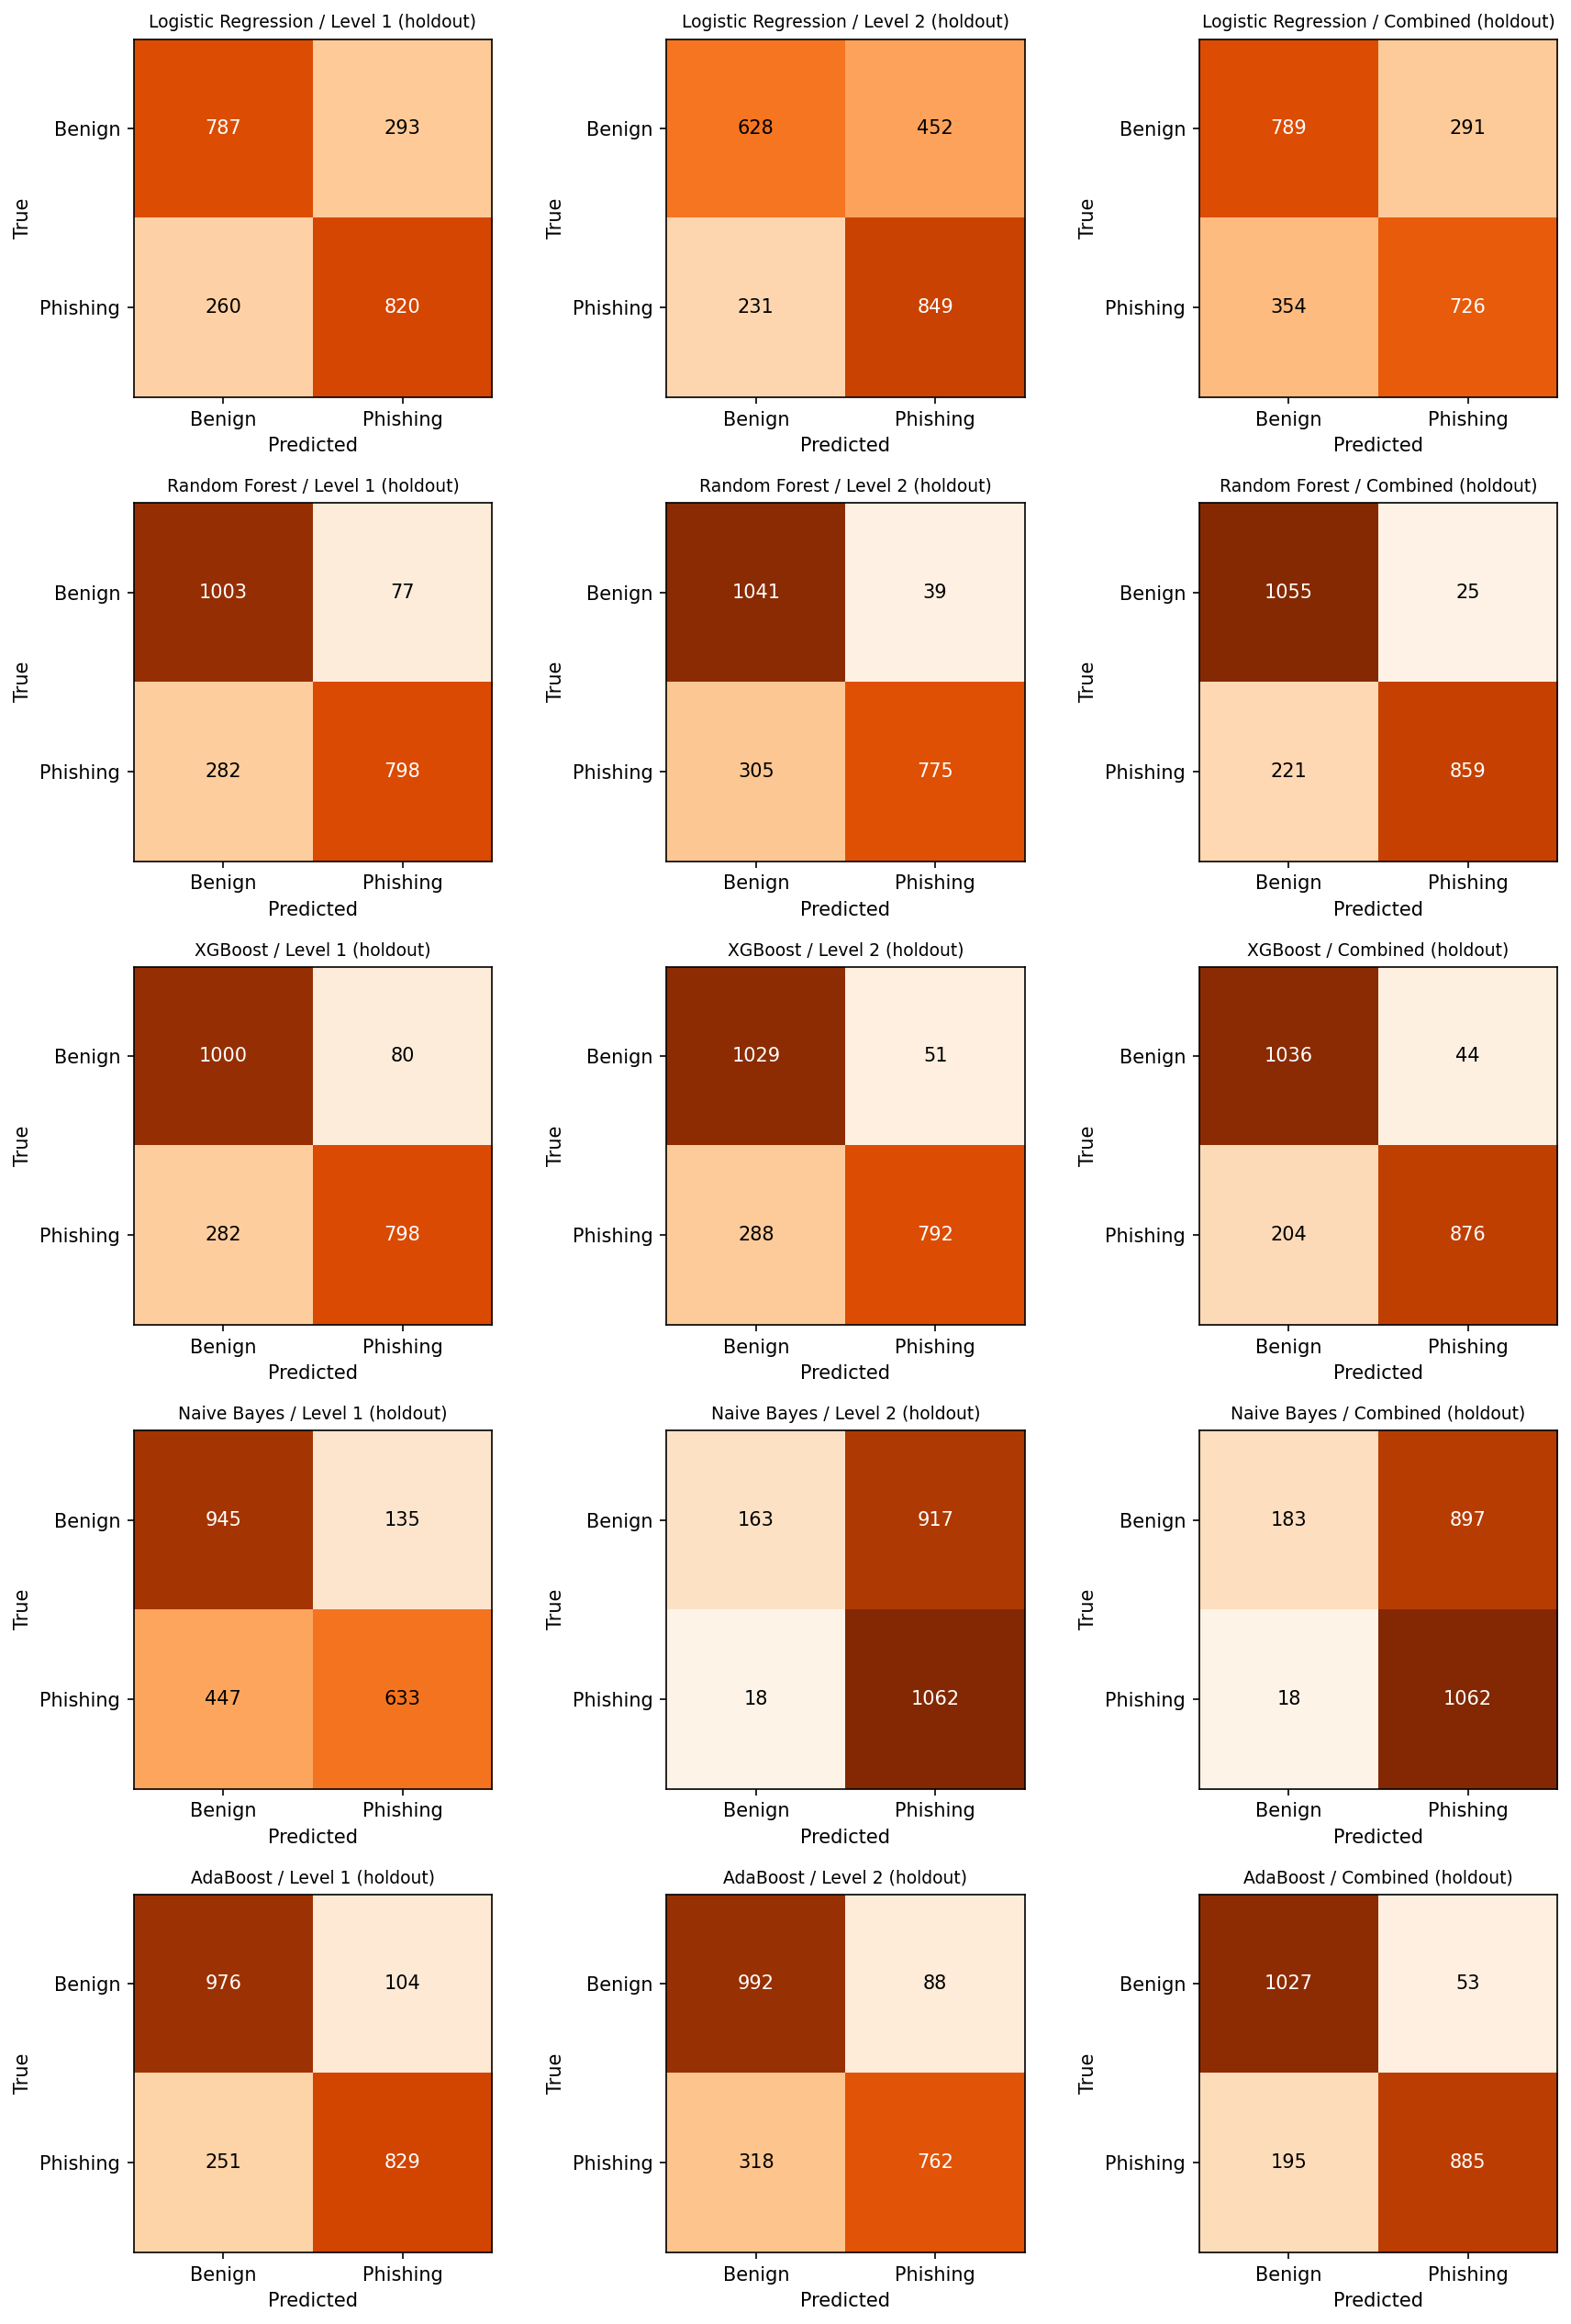

**Supplementary (test set):** a heuristic evasion-indicator slice of the test set (query encoding, redirect or nested URL flags, deep paths/subdomains, or high entropy/token variance relative to training) contains 286 phishing and 164 benign URLs. XGBoost / Combined detected 97.20% of these phishing URLs (baseline 73.08%) with FPR 2.44%. Because the indicators are computed from the same features the models use, this slice is partly circular and is reported only as a supplement to the temporal holdout. Per-slice rates are in `subset_evaluation.csv`; defanged, row-indexed error examples are in `error_examples_defanged.csv`.

In [ ]:
hv=h[['classifier','feature_set','recall','fnr','fpr','f1','fn','fp','recall_change_from_test_pp']].copy()
for col in ['recall','fnr','fpr','f1']:hv[col]=hv[col].map(pct)
hv['recall_change_from_test_pp']=hv.recall_change_from_test_pp.map(lambda x:f'{x:+.2f}')
hv.columns=['Classifier','Features','Recall','FNR','FPR','F1','Missed (FN)','False alarms (FP)','Recall vs. test (pp)']
section(f"## 4. Evasion-heavy holdout: newest phishing URLs ({hc['phishing']:,} phishing, first seen {hd[0]} to {hd[1]}; {hc['benign']:,} benign)\n\n"+mdtable(hv))
chart('10_evasion_holdout_recall_fnr_fpr.png','Recall, FNR and FPR on the evasion-heavy holdout for all 15 combinations at threshold 0.5.')
hpv=hp[['classifier','feature_set','delta_recall_pp','delta_fpr_pp','phishing_newly_caught','phishing_newly_missed','recall_mcnemar_p_holm','fpr_mcnemar_p_holm']].copy()
hpv['delta_recall_pp']=hpv.delta_recall_pp.map(lambda x:f'{x:+.2f}');hpv['delta_fpr_pp']=hpv.delta_fpr_pp.map(lambda x:f'{x:+.2f}')
hpv['recall_mcnemar_p_holm']=hpv.recall_mcnemar_p_holm.map(lambda x:f'{x:.3g}');hpv['fpr_mcnemar_p_holm']=hpv.fpr_mcnemar_p_holm.map(lambda x:f'{x:.3g}')
hpv.columns=['Classifier','Features (vs. Level 1)','ΔRecall (pp)','ΔFPR (pp)','Newly caught','Newly missed','Recall p (Holm)','FPR p (Holm)']
section('### Within-classifier feature comparison on the holdout\n\n'+mdtable(hpv))
hb=H.loc[base.name]; hbest=H.loc[best.combination]
best_l1=m[(m.classifier==best.classifier)&(m.feature_set=='Level 1')].iloc[0]; hbl1=H.loc[best_l1.combination]
sig_up=hp[(hp.feature_set=='Combined')&(hp.delta_recall_pp>0)&(hp.recall_mcnemar_p_holm<.05)].classifier.tolist()
sig_down=hp[(hp.feature_set=='Combined')&(hp.delta_recall_pp<0)&(hp.recall_mcnemar_p_holm<.05)].classifier.tolist()
cheap=hp[(hp.feature_set=='Combined')&(hp.delta_recall_pp>0)&(hp.recall_mcnemar_p_holm<.05)&(hp.delta_fpr_pp<=0)].classifier.tolist()
G=gfpr[(gfpr.evaluation_set=='evasion_holdout')&(gfpr.combination==best.combination)].set_index('benign_group')
D=hdom[hdom.combination==best.combination].set_index('slice')
section(f"""
The evasion holdout tests generalization to phishing URLs **newer than anything in training**. At the 0.5 threshold, the Level 1 baseline caught **{pct(hb.recall)}** of these newest phishing URLs (FNR {pct(hb.fnr)}, {int(hb.fn)} missed) with FPR {pct(hb.fpr)}. The leading test-set model, **{label(best)}**, caught **{pct(hbest.recall)}** (FNR {pct(hbest.fnr)}, {int(hbest.fn)} missed), a change of {hbest.recall_change_from_test_pp:+.2f} pp from its test-set recall, with FPR {pct(hbest.fpr)}. Its own Level 1 version caught {pct(hbl1.recall)} (FPR {pct(hbl1.fpr)}).

Within each classifier, Combined features significantly **increased** holdout recall over Level 1 (exact McNemar on phishing rows, Holm-adjusted p < 0.05) for: **{names(sig_up)}**; of these, FPR did not rise for: **{names(cheap)}**. Combined significantly **decreased** holdout recall for: **{names(sig_down)}**. A recall gain is only useful if false alarms stay acceptable, so the FPR column must be read alongside it; a model that flags almost everything reaches high recall with an unusable FPR.

False alarms on the holdout's benign URLs for {label(best)} were {pct(G.loc['domain_only','fpr'])} on domain-only URLs, {pct(G.loc['light_path','fpr'])} on light-path URLs and {pct(G.loc['obfuscated','fpr'])} on obfuscated-looking benign URLs (per-group rates for every model are in `benign_group_fpr.csv`). The holdout is temporal but not domain-disjoint: {int(Q['evasion holdout phishing URLs whose registered domain occurs in training']):,} of its {hc['phishing']:,} phishing URLs share a registered domain with training URLs. For {label(best)}, recall was {pct(D.loc['domain seen in training','recall'])} on those and {pct(D.loc['domain unseen in training','recall'])} on the {int(D.loc['domain unseen in training','n_phishing']):,} phishing URLs from unseen domains, so part of the holdout performance reflects familiar domains. The holdout's benign URLs are not dated, so its FPR is not a time-based result.
""")
chart('11_evasion_holdout_confusion_matrices_15.png','Confusion matrices for all 15 combinations on the evasion-heavy holdout.')
proxy=s[s.slice=='evasion_indicator_proxy'].set_index('combination')
p1=proxy.loc[best.combination];p0=proxy.loc[base.name]
section(f"""
**Supplementary (test set):** a heuristic evasion-indicator slice of the test set (query encoding, redirect or nested URL flags, deep paths/subdomains, or high entropy/token variance relative to training) contains {int(p1.n_phishing)} phishing and {int(p1.n_benign)} benign URLs. {label(best)} detected {pct(p1.recall)} of these phishing URLs (baseline {pct(p0.recall)}) with FPR {pct(p1.fpr)}. Because the indicators are computed from the same features the models use, this slice is partly circular and is reported only as a supplement to the temporal holdout. Per-slice rates are in `subset_evaluation.csv`; defanged, row-indexed error examples are in `error_examples_defanged.csv`.
""")

,error_type,row_index,probability,evasion_indicator_proxy,url_length,path_depth,domain_entropy,query_encoding_ratio
128,FP,58,0.8262,False,19.0,1.0,3.3219,0.0000
129,FP,73,0.9944,True,130.0,2.0,4.2728,0.0000
130,FP,480,0.6950,False,15.0,0.0,3.3736,0.0000
136,FN,86,0.1394,True,326.0,1.0,3.1899,0.1304
137,FN,126,0.0303,False,23.0,1.0,3.4613,0.0000
138,FN,412,0.0099,False,29.0,2.0,3.3278,0.0000


## 5. Feature importance, fit, and threshold sensitivity

Top five shuffled features for the leading Combined model, measured by decrease in test F1:

| feature | level | f1_drop_mean | f1_drop_std |
| --- | --- | --- | --- |
| path_length | Level 1 | 0.1245 | 0.0018 |
| domain_length | Level 1 | 0.0809 | 0.0061 |
| token_variance | Level 2 | 0.0507 | 0.002 |
| path_depth | Level 2 | 0.0463 | 0.004 |
| domain_entropy | Level 2 | 0.0437 | 0.0007 |

For XGBoost / Combined, shuffling **path_length** caused the largest average F1 drop (12.45 pp). Both lexical and obfuscation-aware columns are inspected in the permutation table. Shuffling measures how the fitted model used the feature in this test set; it does not identify a causal signal or reliably separate contributions of correlated columns. The largest resubstitution-to-test F1 gap was 8.01 pp for XGBoost / Level 2; the resubstitution score is an optimistic fit diagnostic. The leading model had CV F1 94.05% and test F1 94.42%. Close scores are useful as a consistency check but cannot rule out shared-domain or preprocessing effects.

At the stored training-derived threshold (0.57), the leading model's observed recall was 92.35% and FPR was 3.44%, versus 92.86% and 3.83% at 0.5. This sensitivity comparison is secondary; we retained 0.5 as the proposal's primary rule. The model's ROC-AUC was 0.9822, average precision 0.9857, and Brier score 0.0447. The output score estimates **phishing** likelihood under the model. The experiment does not establish that it measures intent to evade or that its probabilities will be calibrated at real-world phishing prevalence.

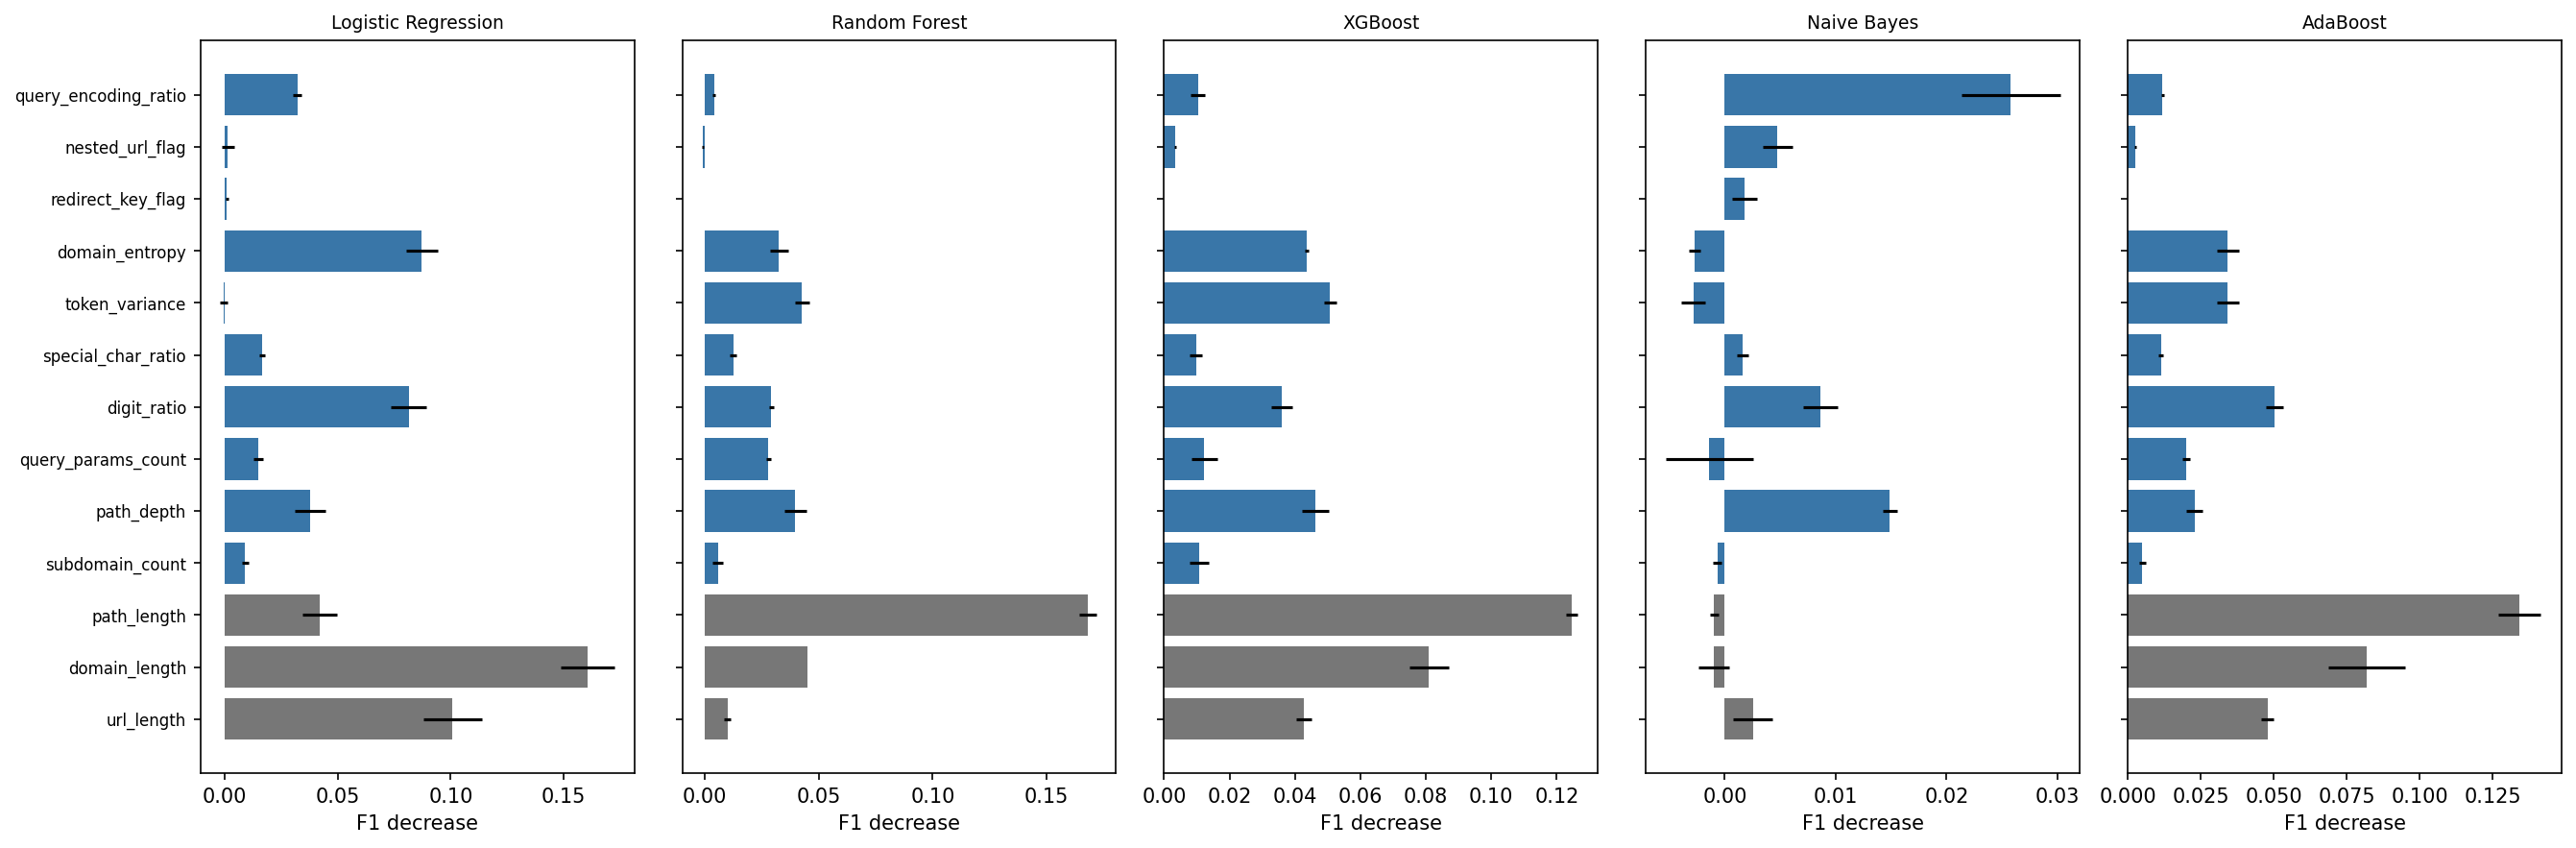

In [ ]:
# Explain concrete error patterns with aggregate counts; this avoids exposing active URLs.
errors=read('error_examples_defanged')
v=errors[errors.combination==best.combination]
showcols=['error_type','row_index','probability','evasion_indicator_proxy','url_length','path_depth','domain_entropy','query_encoding_ratio']
display(v[showcols].groupby('error_type').head(3).round(4))
imp_top=imp[imp.classifier==best.classifier].nlargest(5,'f1_drop_mean')
imp_display=imp_top[['feature','level','f1_drop_mean','f1_drop_std']].round(4)
section('## 5. Feature importance, fit, and threshold sensitivity\n\n'+
        'Top five shuffled features for the leading Combined model, measured by decrease in test F1:\n\n'+mdtable(imp_display))
tr=t.set_index('combination').loc[best.combination]
large_gap=m.loc[m.train_minus_test_f1.idxmax()]
section(f"""
For {label(best)}, shuffling **{imp_top.iloc[0].feature}** caused the largest average F1 drop ({100*imp_top.iloc[0].f1_drop_mean:.2f} pp). Both lexical and obfuscation-aware columns are inspected in the permutation table. Shuffling measures how the fitted model used the feature in this test set; it does not identify a causal signal or reliably separate contributions of correlated columns. The largest resubstitution-to-test F1 gap was {100*large_gap.train_minus_test_f1:.2f} pp for {label(large_gap)}; the resubstitution score is an optimistic fit diagnostic. The leading model had CV F1 {pct(best.cv_f1)} and test F1 {pct(best.f1)}. Close scores are useful as a consistency check but cannot rule out shared-domain or preprocessing effects.

At the stored training-derived threshold ({tr.threshold:.2f}), the leading model's observed recall was {pct(tr.recall)} and FPR was {pct(tr.fpr)}, versus {pct(best.recall)} and {pct(best.fpr)} at 0.5. This sensitivity comparison is secondary; we retained 0.5 as the proposal's primary rule. The model's ROC-AUC was {best.roc_auc:.4f}, average precision {best.average_precision:.4f}, and Brier score {best.brier:.4f}. The output score estimates **phishing** likelihood under the model. The experiment does not establish that it measures intent to evade or that its probabilities will be calibrated at real-world phishing prevalence.
""")
chart('06_permutation_importance.png','Permutation importance for the five Combined models, three shuffled repetitions.')

## 6. Resource tradeoffs

| Model | Training s (original) | Peak RSS MiB (original) | Original mean ms/URL | Rerun mean / p95 ms/URL | Model MiB | Extraction s / 10k (original) |
| --- | --- | --- | --- | --- | --- | --- |
| Logistic Regression / Level 1 | 6.43 | 275.2 | 1.369 | 1.738 / 4.891 | 0.003 | 0.232 |
| XGBoost / Combined | 18.83 | 337.9 | 1.198 | 2.689 / 3.632 | 0.765 | 1.009 |
| Random Forest / Combined | 99.11 | 308.8 | 17.239 | 25.363 / 38.241 | 23.060 | 1.009 |
| AdaBoost / Combined | 118.90 | 338.1 | 30.785 | 42.018 / 64.334 | 0.286 | 1.009 |

XGBoost / Combined took 18.83 s for the original grid search and refit, compared with 99.11 s for Random Forest / Combined. Their original model-only mean inference times were 1.198 and 17.239 ms per URL, respectively. In the separate evaluation runtime, the observed means were 2.689 and 25.363 ms per URL. The models occupied 0.765 and 23.060 MiB on disk. Training peak RSS includes the original Python process and previously retained models; it is not the memory attributable solely to each fitted classifier. Extraction times come from the rounded Module 3–4 profile; they are not new measurements and do not include browsing or deployment. The timings support a comparison of this offline experiment. They cannot establish browser, gateway, or deep-learning performance.

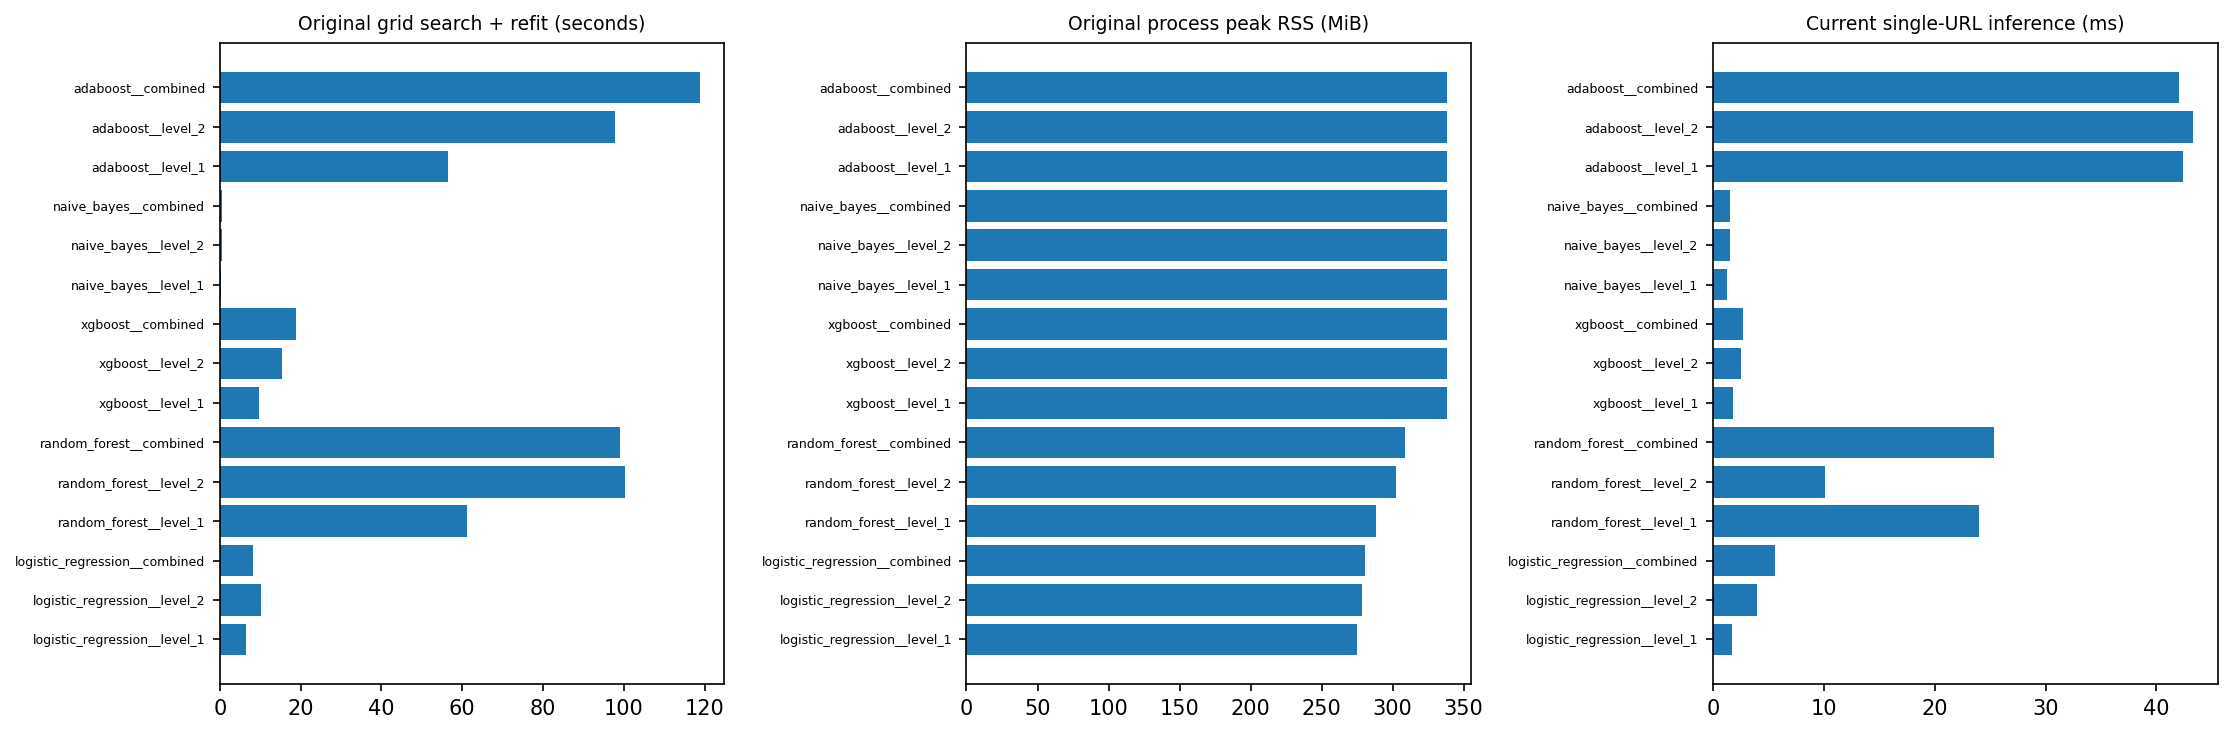

In [ ]:
resource_view=[]
for k in [base.name,best.combination,second.combination,'adaboost__combined']:
    z=R.loc[k]
    resource_view.append({'Model':label(M.loc[k]),'Training s (original)':f'{z.training_time_s_historical:.2f}',
     'Peak RSS MiB (original)':f'{z.training_peak_rss_mb_historical:.1f}',
     'Original mean ms/URL':f'{z.inference_ms_per_url_historical:.3f}',
     'Rerun mean / p95 ms/URL':f'{z.inference_mean_ms_current:.3f} / {z.inference_p95_ms_current:.3f}',
     'Model MiB':f'{z.model_size_mb:.3f}',
     'Extraction s / 10k (original)':f'{z.extraction_10000_urls_s_historical_rounded:.3f}'})
section('## 6. Resource tradeoffs\n\n'+mdtable(pd.DataFrame(resource_view)))
best_cost=R.loc[best.combination];second_cost=R.loc[second.combination]
section(f"""
{label(best)} took {best_cost.training_time_s_historical:.2f} s for the original grid search and refit, compared with {second_cost.training_time_s_historical:.2f} s for {label(second)}. Their original model-only mean inference times were {best_cost.inference_ms_per_url_historical:.3f} and {second_cost.inference_ms_per_url_historical:.3f} ms per URL, respectively. In the separate evaluation runtime, the observed means were {best_cost.inference_mean_ms_current:.3f} and {second_cost.inference_mean_ms_current:.3f} ms per URL. The models occupied {best_cost.model_size_mb:.3f} and {second_cost.model_size_mb:.3f} MiB on disk. Training peak RSS includes the original Python process and previously retained models; it is not the memory attributable solely to each fitted classifier. Extraction times come from the rounded Module 3–4 profile; they are not new measurements and do not include browsing or deployment. The timings support a comparison of this offline experiment. They cannot establish browser, gateway, or deep-learning performance.
""")
chart('08_resource_profile.png','Historical training cost and current model-only inference latency for the 15 combinations.')

In [ ]:
hbest=H.loc[best.combination]; hb=H.loc[base.name]
section(f"""
## 7. Preliminary conclusion and work before final evaluation

On the test set, {label(best)} had the highest observed F1 ({pct(best.f1)}, versus {pct(base.f1)} for the baseline), followed by {label(second)} ({pct(second.f1)}). On the evasion-heavy holdout of the newest phishing URLs, {label(best)} caught {pct(hbest.recall)} of phishing URLs with FPR {pct(hbest.fpr)}, versus {pct(hb.recall)} recall and {pct(hb.fpr)} FPR for the baseline. Section 3 lists the classifiers for which Combined features improved F1 and FPR on the test set, and Section 4 the classifiers for which they improved recall on the holdout; where these agree, the results support the finding that the Level 2 features add useful information to the lexical features for those classifiers. Where they disagree, or where a recall gain comes with a large rise in false alarms, the gain is model-dependent and should not be generalized.

These results remain provisional. The test set was displayed in Modules 6 and 7, so only the evasion holdout is a first look. The holdout is temporal for phishing URLs but not for benign URLs (the top-site lists carry no collection dates), and part of its phishing URLs share a registered domain with training URLs. The source rankings/feeds and balanced class ratio also differ from live traffic, so precision here should not be extrapolated to deployment. Full-string lowercasing can change case-sensitive paths and encoded payloads. The panel should confirm the 3/10 feature allocation and the proposal's Table 4.1 definitions.

Already in place: de-duplication after normalization ({int(Q['duplicate normalized URLs'])} duplicates remain), first-seen dates and source provenance for every phishing URL, scaling fitted inside each training fold with the full pipelines persisted, and a temporal evasion holdout excluded from training and tuning. Before final evaluation, we should confirm the gains on an independently collected, domain-disjoint set of later phishing URLs with dated benign counterparts, report detection and false alarm rates with their support, and re-measure resource costs on the target hardware.

**Evidence trail:** `performance_comparison_15.csv`, `evasion_holdout_comparison_15.csv`, `evasion_holdout_paired_comparisons.csv`, `benign_group_fpr.csv`, `evasion_holdout_domain_overlap.csv`, `paired_comparisons.csv`, `subset_evaluation.csv`, `resource_comparison.csv`, `tuned_threshold_sensitivity.csv`, `artifact_verification.csv`, and `evaluation_metadata.json` in `Results/milestone8/`. All plots and scores use the saved Module 7 models.
""")
report='\n\n'.join(sections)+'\n'
(OUT/'preliminary_findings_draft.md').write_text(report,encoding='utf-8')
assert len(sections)>=16 and 'Preliminary conclusion' in report and 'Full comparison' in report and 'Evasion-heavy holdout' in report
print('Milestone 9 complete: draft and ablation table saved to',OUT)

## 7. Preliminary conclusion and work before final evaluation

On the test set, XGBoost / Combined had the highest observed F1 (94.42%, versus 60.59% for the baseline), followed by Random Forest / Combined (93.90%). On the evasion-heavy holdout of the newest phishing URLs, XGBoost / Combined caught 81.11% of phishing URLs with FPR 4.07%, versus 75.93% recall and 27.13% FPR for the baseline. Section 3 lists the classifiers for which Combined features improved F1 and FPR on the test set, and Section 4 the classifiers for which they improved recall on the holdout; where these agree, the results support the finding that the Level 2 features add useful information to the lexical features for those classifiers. Where they disagree, or where a recall gain comes with a large rise in false alarms, the gain is model-dependent and should not be generalized.

These results remain provisional. The test set was displayed in Modules 6 and 7, so only the evasion holdout is a first look. The holdout is temporal for phishing URLs but not for benign URLs (the top-site lists carry no collection dates), and part of its phishing URLs share a registered domain with training URLs. The source rankings/feeds and balanced class ratio also differ from live traffic, so precision here should not be extrapolated to deployment. Full-string lowercasing can change case-sensitive paths and encoded payloads. The panel should confirm the 3/10 feature allocation and the proposal's Table 4.1 definitions.

Already in place: de-duplication after normalization (0 duplicates remain), first-seen dates and source provenance for every phishing URL, scaling fitted inside each training fold with the full pipelines persisted, and a temporal evasion holdout excluded from training and tuning. Before final evaluation, we should confirm the gains on an independently collected, domain-disjoint set of later phishing URLs with dated benign counterparts, report detection and false alarm rates with their support, and re-measure resource costs on the target hardware.

**Evidence trail:** `performance_comparison_15.csv`, `evasion_holdout_comparison_15.csv`, `evasion_holdout_paired_comparisons.csv`, `benign_group_fpr.csv`, `evasion_holdout_domain_overlap.csv`, `paired_comparisons.csv`, `subset_evaluation.csv`, `resource_comparison.csv`, `tuned_threshold_sensitivity.csv`, `artifact_verification.csv`, and `evaluation_metadata.json` in `Results/milestone8/`. All plots and scores use the saved Module 7 models.

Milestone 9 complete: draft and ablation table saved to /content/PhishEvade/Results/milestone9
